In [8]:
library('tidymodels')
library('palmerpenguins')
library('vip')

theme_set(theme_gray(base_size = 16))

In [9]:
penguins2 = penguins |>
    drop_na()

penguins2 |> head()

  species island    bill_length_mm bill_depth_mm flipper_length_mm body_mass_g
1 Adelie  Torgersen 39.1           18.7          181               3750       
2 Adelie  Torgersen 39.5           17.4          186               3800       
3 Adelie  Torgersen 40.3           18.0          195               3250       
4 Adelie  Torgersen 36.7           19.3          193               3450       
5 Adelie  Torgersen 39.3           20.6          190               3650       
6 Adelie  Torgersen 38.9           17.8          181               3625       
  sex    year
1 male   2007
2 female 2007
3 female 2007
4 female 2007
5 male   2007
6 female 2007

## Use random forests to model `bill_length_mm`

In [11]:
mod = rand_forest() |> 
    set_engine('ranger', importance = 'impurity') |>
    set_mode('regression')

In [17]:
rec = recipe(bill_length_mm ~ ., data = penguins2) |>
    step_rm(year) |>
    step_dummy(sex, island, species)

rec_prepped = prep(rec)

rec_prepped |> juice() |> head()

  bill_depth_mm flipper_length_mm body_mass_g bill_length_mm sex_male
1 18.7          181               3750        39.1           1       
2 17.4          186               3800        39.5           0       
3 18.0          195               3250        40.3           0       
4 19.3          193               3450        36.7           0       
5 20.6          190               3650        39.3           1       
6 17.8          181               3625        38.9           0       
  island_Dream island_Torgersen species_Chinstrap species_Gentoo
1 0            1                0                 0             
2 0            1                0                 0             
3 0            1                0                 0             
4 0            1                0                 0             
5 0            1                0                 0             
6 0            1                0                 0             

In [18]:
wf = workflow() |> 
  add_recipe(rec) |> 
  add_model(mod)

wf_fit = wf |> fit(data = penguins2)

wf_fit

══ Workflow [trained] ══════════════════════════════════════════════════════════
Preprocessor: Recipe
Model: rand_forest()

── Preprocessor ────────────────────────────────────────────────────────────────
2 Recipe Steps

• step_rm()
• step_dummy()

── Model ───────────────────────────────────────────────────────────────────────
Ranger result

Call:
 ranger::ranger(x = maybe_data_frame(x), y = y, importance = "impurity",      num.threads = 1, verbose = FALSE, seed = sample.int(10^5,          1)) 

Type:                             Regression 
Number of trees:                  500 
Sample size:                      333 
Number of independent variables:  8 
Mtry:                             2 
Target node size:                 5 
Variable importance mode:         impurity 
Splitrule:                        variance 
OOB prediction error (MSE):       5.573083 
R squared (OOB):                  0.8136487 

In [19]:
outcomes = augment(wf_fit |> extract_fit_parsnip(), 
                   new_data = rec_prepped |> juice())

outcomes |> head()

  .pred    .resid     bill_depth_mm flipper_length_mm body_mass_g
1 39.26313 -0.1631277 18.7          181               3750       
2 38.02484  1.4751558 17.4          186               3800       
3 38.88610  1.4139050 18.0          195               3250       
4 37.76349 -1.0634851 19.3          193               3450       
5 38.78794  0.5120580 20.6          190               3650       
6 38.29640  0.6036022 17.8          181               3625       
  bill_length_mm sex_male island_Dream island_Torgersen species_Chinstrap
1 39.1           1        0            1                0                
2 39.5           0        0            1                0                
3 40.3           0        0            1                0                
4 36.7           0        0            1                0                
5 39.3           1        0            1                0                
6 38.9           0        0            1                0                
  species_Gentoo
1 0

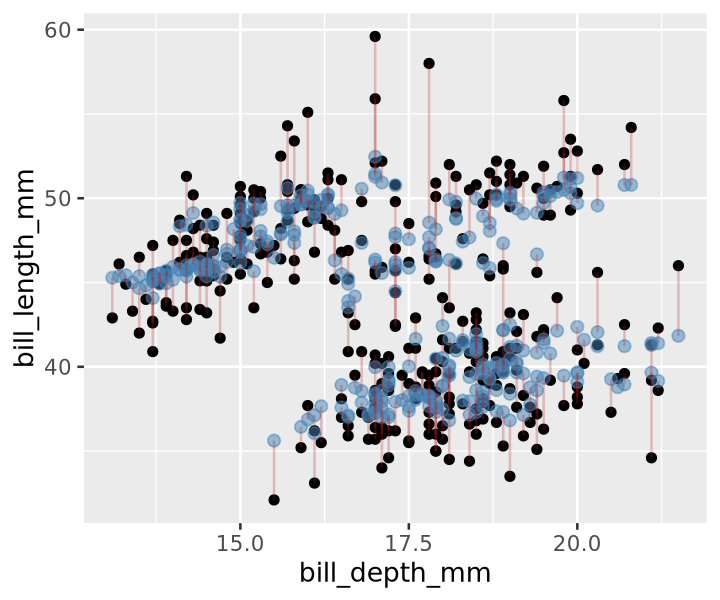

In [20]:
options(repr.plot.width = 6, repr.plot.height = 5)

ggplot(outcomes) +
    geom_point(aes(x = bill_depth_mm, y = bill_length_mm)) + 
    geom_point(aes(x = bill_depth_mm, y = .pred), color = 'steelblue', size = 3,
               alpha = 0.5) +
    geom_segment(aes(x = bill_depth_mm, xend = bill_depth_mm, y = .pred, yend = bill_length_mm), 
                 color = 'firebrick',
                 alpha = 0.25)

## Visualize feature importance

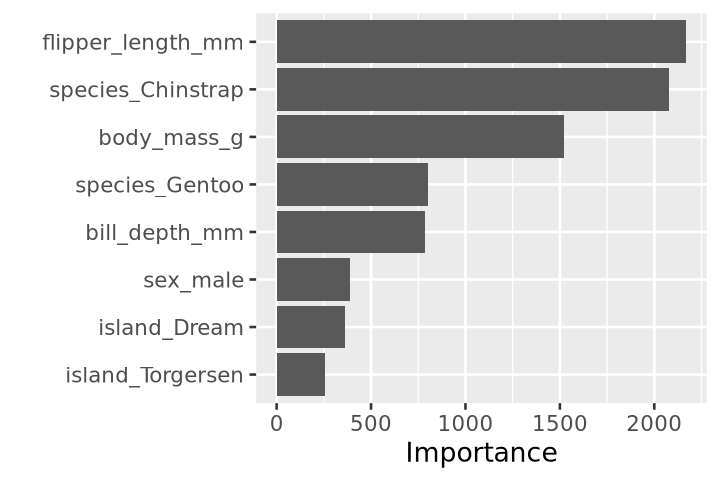

In [21]:
options(repr.plot.width = 6, repr.plot.height = 4)

wf_fit |> 
  extract_fit_parsnip() |> 
  vip()

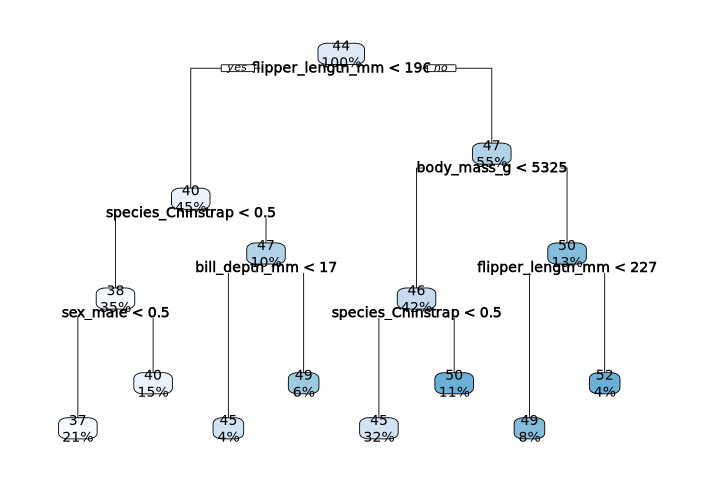

In [22]:
mod_tree = decision_tree(tree_depth = 3, cost_complexity = 0.001) |>
    set_engine('rpart') |>
    set_mode('regression')

wf_tree = workflow() |>
    add_recipe(rec) |>
    add_model(mod_tree)

wf_tree_fit = wf_tree |> fit(data = penguins2)

wf_tree_fit |>
    extract_fit_engine() |>
    rpart.plot::rpart.plot(roundint = FALSE, cex = 0.7)